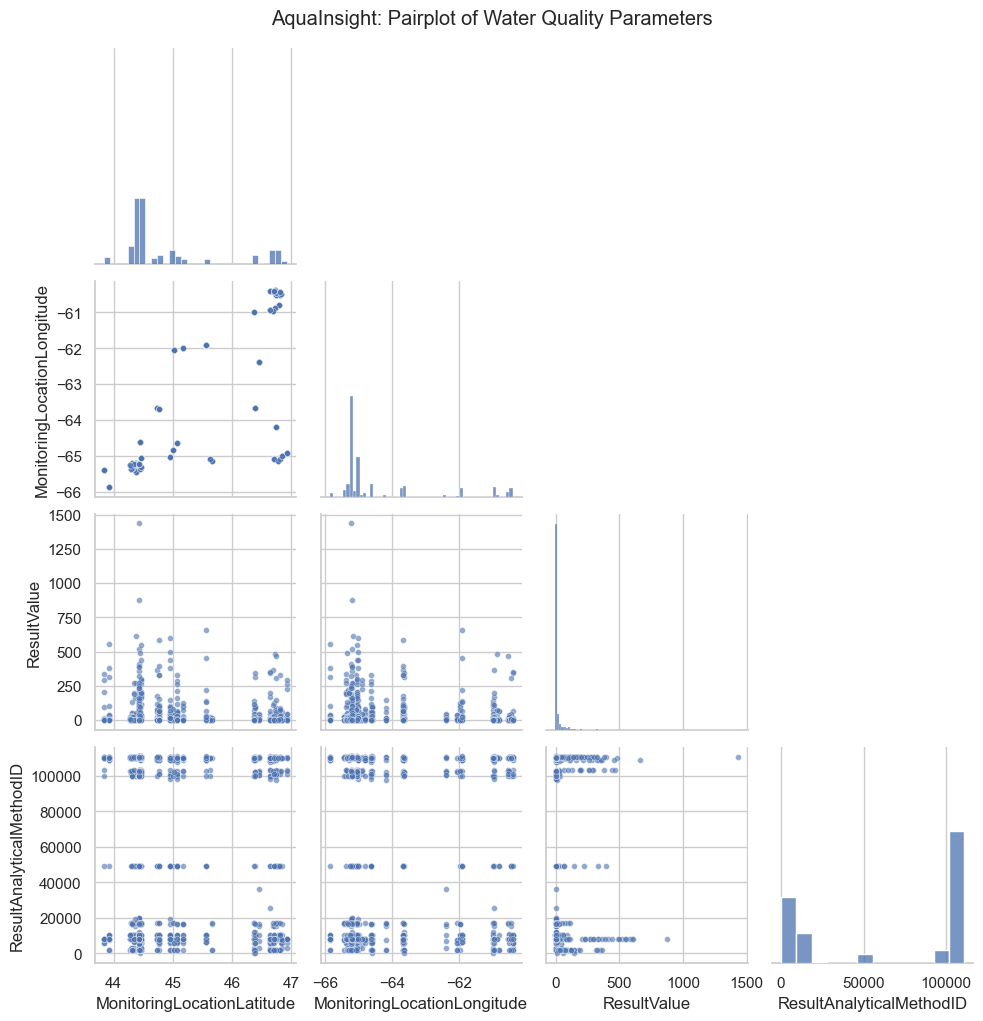

Pairplot saved as: pairplot_water_quality.png

Quick numerical summary:
       MonitoringLocationLatitude  MonitoringLocationLongitude  ResultValue  \
count                   229916.00                    229916.00    229916.00   
mean                        44.92                       -64.39        21.46   
std                          0.87                         1.51        97.37   
min                         43.84                       -65.87        -8.11   
25%                         44.42                       -65.22         0.24   
50%                         44.45                       -65.14         1.20   
75%                         45.06                       -64.18         6.63   
max                         46.93                       -60.39     10847.00   

       ResultAnalyticalMethodID  
count                 229916.00  
mean                   67431.28  
std                    48395.61  
min                        5.00  
25%                     8246.00  
50%         

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


OUTPUT_FILE = "pairplot_water_quality.png"

# Read the dataset
df = pd.read_csv("water Quality.csv")

# Keep numerical columns because pairplots are meant for numeric comparisons
numeric_df = df.select_dtypes(include="number").copy()

# Remove columns that contain no variation; they do not help show relationships
numeric_df = numeric_df.loc[:, numeric_df.nunique(dropna=True) > 1]

if numeric_df.shape[1] < 2:
    raise ValueError("At least two useful numerical columns are required for a pairplot.")

# Pairplots can become slow and crowded with many columns.
# If needed, select important columns manually, for example:
# numeric_df = numeric_df[["pH", "Turbidity", "DissolvedOxygen", "Conductivity"]]

# Use a sample for a clearer and faster plot when the dataset is very large
if len(numeric_df) > 2000:
    plot_df = numeric_df.sample(n=2000, random_state=42)
else:
    plot_df = numeric_df

sns.set_theme(style="whitegrid")
plot = sns.pairplot(
    plot_df,
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.6, "s": 18}
)
plot.fig.suptitle("AquaInsight: Pairplot of Water Quality Parameters", y=1.02)
plot.savefig(OUTPUT_FILE, dpi=300, bbox_inches="tight")
plt.show()

print(f"Pairplot saved as: {OUTPUT_FILE}")
print("\nQuick numerical summary:")
print(numeric_df.describe().round(2))

print(
    "\nHow to interpret: Look for upward/downward patterns, curved patterns, "
    "clusters, and points far away from the main group. A visual outlier should "
    "be checked against the original record before removing it."
)
